# Comparative ML Analysis: NYC Airbnb Price Prediction
### Classical ML vs Deep Learning — Individual Presentation Notebook
**Dataset:** NYC Airbnb Open Data 2019  
**Task:** Regression — predicting listing price  
**Models:** Polynomial Regression (degree 2) vs Feedforward Neural Network (PyTorch)

## Section 1: Imports and Configuration

In [1]:
# ── Standard library ─────────────────────────────────────────────────────────
import warnings
import os

# ── Data handling ─────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd

# ── Visualisation ─────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import seaborn as sns

# ── Scikit-learn (classical ML) ───────────────────────────────────────────────
from sklearn.preprocessing import LabelEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# ── PyTorch (deep learning) ───────────────────────────────────────────────────
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# ── Explainability ────────────────────────────────────────────────────────────
import shap

# ── Reproducibility ───────────────────────────────────────────────────────────
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

warnings.filterwarnings('ignore')
os.makedirs('figures', exist_ok=True)

print('All libraries loaded successfully.')
print(f'PyTorch version: {torch.__version__}')

All libraries loaded successfully.
PyTorch version: 2.14.1


## Section 2: Data Loading and Preprocessing

WHY these preprocessing decisions?
- **Log-transform price**: Price is heavily right-skewed. Log transformation makes the distribution approximately normal, which improves both linear and neural models (James et al., 2021).
- **Drop last_review**: High missingness and date parsing adds complexity without meaningful signal for price prediction.
- **Fill reviews_per_month NaN with 0**: Listings with no reviews have zero review activity — this is a meaningful imputation, not a guess.
- **Price filter (above $0 and up to $1,000)**: Zero-priced listings are invalid, and extreme prices above $1,000/night (about 0.5% of listings) would distort both models.

In [2]:
# ── Load dataset ──────────────────────────────────────────────────────────────
# WHY this dataset: the prepared version includes the distance_times_square_km
# feature engineered during group work preprocessing.
from pathlib import Path

DATA_DIR = Path.home() / 'Desktop' / 'airbnb_ml'
os.chdir(DATA_DIR)                       # run from the project folder
os.makedirs('figures', exist_ok=True)    # figures saved alongside the notebook

matches = sorted(DATA_DIR.glob('AB_NYC_2019_prepared_with_distance*.csv'))
print('Dataset file found:', [m.name for m in matches])
df = pd.read_csv(matches[0])

print(f'Loaded {len(df):,} rows × {len(df.columns)} columns')
print(f'Columns: {list(df.columns)}')

Dataset file found: ['AB_NYC_2019_prepared_with_distance (1).csv']
Loaded 48,884 rows × 13 columns
Columns: ['neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'distance_times_square_km']


In [3]:
# ── Preprocessing ─────────────────────────────────────────────────────────────

# Drop the date column — high missingness, minimal predictive value
if 'last_review' in df.columns:
    df.drop(columns=['last_review'], inplace=True)

# Fill missing review frequency with 0 (listing has had no reviews yet)
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

# Filter unrealistic prices
df = df[(df['price'] > 0) & (df['price'] <= 1000)].copy()

# Log-transform price to reduce right skew
# WHY log1p: avoids log(0) issues; np.expm1() reverses it for interpretation
df['log_price'] = np.log1p(df['price'])

# Encode categorical variables
# WHY LabelEncoder not OneHot: keeps feature count low for polynomial expansion
le_room = LabelEncoder()
le_borough = LabelEncoder()
df['room_type_enc'] = le_room.fit_transform(df['room_type'])
df['borough_enc'] = le_borough.fit_transform(df['neighbourhood_group'])

print(f'After filtering: {len(df):,} rows remain')
print(f'Room types: {dict(zip(le_room.classes_, le_room.transform(le_room.classes_)))}')
print(f'Boroughs: {dict(zip(le_borough.classes_, le_borough.transform(le_borough.classes_)))}')

After filtering: 48,645 rows remain
Room types: {'Entire home/apt': np.int64(0), 'Private room': np.int64(1), 'Shared room': np.int64(2)}
Boroughs: {'Bronx': np.int64(0), 'Brooklyn': np.int64(1), 'Manhattan': np.int64(2), 'Queens': np.int64(3), 'Staten Island': np.int64(4)}


In [4]:
# ── Feature selection and train/test split ────────────────────────────────────

FEATURES = [
    'distance_times_square_km',  # Distance from Times Square (engineered feature)
    'room_type_enc',             # Type of room (encoded)
    'borough_enc',               # NYC borough (encoded)
    'minimum_nights',            # Host-set minimum stay
    'reviews_per_month',         # Proxy for popularity / booking activity
    'availability_365',          # Annual availability (supply signal)
]
TARGET = 'log_price'

X = df[FEATURES].values
y = df[TARGET].values

# 80/20 split — stratify on borough to preserve geographic distribution
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=df['neighbourhood_group']
)

# Scale features — WHY StandardScaler: both polynomial interaction terms and
# neural network weights are sensitive to feature magnitude. Scaling to zero
# mean / unit variance ensures no single feature dominates training.
# IMPORTANT: fit ONLY on training data to prevent data leakage.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)  # transform only — no fit

print(f'Training set: {X_train_scaled.shape[0]:,} samples')
print(f'Test set:     {X_test_scaled.shape[0]:,} samples')
print(f'Features ({len(FEATURES)}): {FEATURES}')

Training set: 38,916 samples
Test set:     9,729 samples
Features (6): ['distance_times_square_km', 'room_type_enc', 'borough_enc', 'minimum_nights', 'reviews_per_month', 'availability_365']


## Section 3: Exploratory Data Analysis

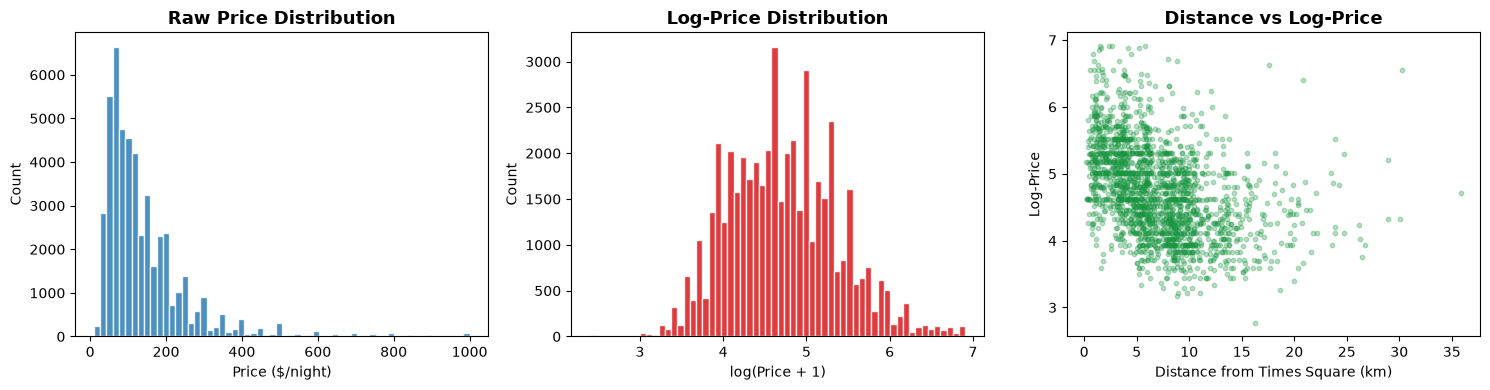

Saved: figures/eda_distributions.png


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Raw price distribution
axes[0].hist(df['price'], bins=60, color='#2c7bb6', edgecolor='white', alpha=0.85)
axes[0].set_title('Raw Price Distribution', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Price ($/night)')
axes[0].set_ylabel('Count')

# Log-price distribution
axes[1].hist(df['log_price'], bins=60, color='#d7191c', edgecolor='white', alpha=0.85)
axes[1].set_title('Log-Price Distribution', fontsize=13, fontweight='bold')
axes[1].set_xlabel('log(Price + 1)')
axes[1].set_ylabel('Count')

# Distance vs price
sample = df.sample(2000, random_state=RANDOM_STATE)
axes[2].scatter(sample['distance_times_square_km'], sample['log_price'],
                alpha=0.3, s=10, color='#1a9641')
axes[2].set_title('Distance vs Log-Price', fontsize=13, fontweight='bold')
axes[2].set_xlabel('Distance from Times Square (km)')
axes[2].set_ylabel('Log-Price')

plt.tight_layout()
plt.savefig('figures/eda_distributions.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: figures/eda_distributions.png')

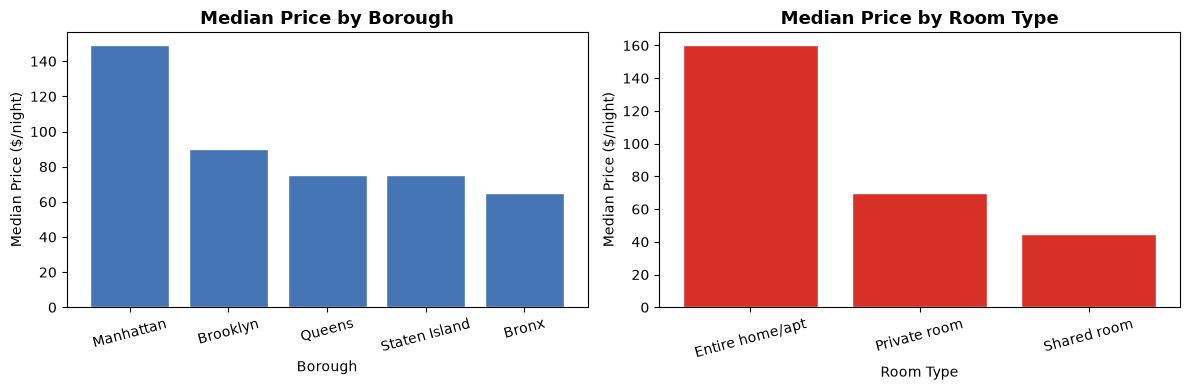

Saved: figures/eda_categories.png


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Median price by borough
borough_medians = df.groupby('neighbourhood_group')['price'].median().sort_values(ascending=False)
axes[0].bar(borough_medians.index, borough_medians.values, color='#4575b4', edgecolor='white')
axes[0].set_title('Median Price by Borough', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Borough')
axes[0].set_ylabel('Median Price ($/night)')
axes[0].tick_params(axis='x', rotation=15)

# Median price by room type
room_medians = df.groupby('room_type')['price'].median().sort_values(ascending=False)
axes[1].bar(room_medians.index, room_medians.values, color='#d73027', edgecolor='white')
axes[1].set_title('Median Price by Room Type', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Room Type')
axes[1].set_ylabel('Median Price ($/night)')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.savefig('figures/eda_categories.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: figures/eda_categories.png')

## Section 4: Model 1 — Polynomial Regression (Classical ML)

**Why Polynomial Regression (degree 2)?**
Polynomial regression extends ordinary linear regression by adding interaction terms between features, allowing the model to capture non-linear relationships without abandoning the interpretability benefits of a linear framework (James et al., 2021). Degree 2 was selected because it captures curvature in the price–distance relationship without the overfitting risk of higher degrees. This model was also used in the group project, providing continuity for comparison.

In [7]:
# ── Build polynomial regression pipeline ──────────────────────────────────────
# WHY Pipeline: ensures PolynomialFeatures expansion is applied consistently
# inside cross-validation folds, preventing data leakage from the expansion step.

poly_pipeline = Pipeline([
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('linear', LinearRegression())
])

# ── 5-fold cross-validation ───────────────────────────────────────────────────
# WHY k=5: balances bias-variance trade-off; standard in applied ML literature
# (Kohavi, 1995). Fewer folds risk high bias; more folds add computational cost.

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

poly_rmse_scores = []
poly_mae_scores  = []
poly_r2_scores   = []

for fold, (train_idx, val_idx) in enumerate(kf.split(X_train_scaled), 1):
    X_fold_train, X_fold_val = X_train_scaled[train_idx], X_train_scaled[val_idx]
    y_fold_train, y_fold_val = y_train[train_idx], y_train[val_idx]

    poly_pipeline.fit(X_fold_train, y_fold_train)
    y_pred = poly_pipeline.predict(X_fold_val)

    rmse = np.sqrt(mean_squared_error(y_fold_val, y_pred))
    mae  = mean_absolute_error(y_fold_val, y_pred)
    r2   = r2_score(y_fold_val, y_pred)

    poly_rmse_scores.append(rmse)
    poly_mae_scores.append(mae)
    poly_r2_scores.append(r2)
    print(f'  Fold {fold}: RMSE={rmse:.4f}  MAE={mae:.4f}  R²={r2:.4f}')

print(f'\n5-Fold CV — Polynomial Regression:')
print(f'  RMSE: {np.mean(poly_rmse_scores):.4f} ± {np.std(poly_rmse_scores):.4f}')
print(f'  MAE:  {np.mean(poly_mae_scores):.4f} ± {np.std(poly_mae_scores):.4f}')
print(f'  R²:   {np.mean(poly_r2_scores):.4f} ± {np.std(poly_r2_scores):.4f}')

  Fold 1: RMSE=0.4568  MAE=0.3343  R²=0.5267
  Fold 2: RMSE=0.4494  MAE=0.3365  R²=0.5509
  Fold 3: RMSE=0.4420  MAE=0.3312  R²=0.5467
  Fold 4: RMSE=0.4469  MAE=0.3362  R²=0.5557
  Fold 5: RMSE=0.4536  MAE=0.3264  R²=0.5115

5-Fold CV — Polynomial Regression:
  RMSE: 0.4497 ± 0.0051
  MAE:  0.3329 ± 0.0038
  R²:   0.5383 ± 0.0166


In [8]:
# ── Final fit on full training set and test evaluation ────────────────────────
poly_pipeline.fit(X_train_scaled, y_train)
y_pred_poly_test = poly_pipeline.predict(X_test_scaled)

poly_test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_poly_test))
poly_test_mae  = mean_absolute_error(y_test, y_pred_poly_test)
poly_test_r2   = r2_score(y_test, y_pred_poly_test)

print('Polynomial Regression — Hold-out Test Set Results:')
print(f'  RMSE: {poly_test_rmse:.4f}')
print(f'  MAE:  {poly_test_mae:.4f}')
print(f'  R²:   {poly_test_r2:.4f}')

Polynomial Regression — Hold-out Test Set Results:
  RMSE: 0.4418
  MAE:  0.3319
  R²:   0.5528


## Section 5: Model 2 — Feedforward Neural Network (Deep Learning)

**Why a Feedforward Neural Network?**
Neural networks learn complex, high-order feature interactions automatically without requiring explicit polynomial expansion (Goodfellow et al., 2016). The architecture chosen — three hidden layers with ReLU activations and dropout regularisation — is well-suited to tabular regression tasks where inter-feature relationships may be non-trivial (Shwartz-Ziv & Armon, 2022).

**Architecture choices:**
- **ReLU activations**: Mitigates vanishing gradient problem; computationally efficient (LeCun et al., 2015)
- **Dropout (0.2)**: Regularisation to reduce overfitting; randomly zeroes 20% of neurons per forward pass
- **Adam optimiser**: Adaptive learning rate; outperforms SGD on most tabular tasks (Kingma & Ba, 2015)
- **Layer sizes 64→32→16→1**: Funnel architecture that progressively compresses feature representations

In [9]:
# ── Network architecture ──────────────────────────────────────────────────────

class AirbnbNet(nn.Module):
    """
    Feedforward neural network for Airbnb price regression.
    
    Architecture: 6 → 64 → 32 → 16 → 1
    Regularisation: Dropout(0.2) after each hidden layer
    """
    def __init__(self, input_dim: int):
        super(AirbnbNet, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.network(x).squeeze(1)


# ── Hyperparameters ───────────────────────────────────────────────────────────
LEARNING_RATE = 0.001
BATCH_SIZE    = 256
EPOCHS        = 50
INPUT_DIM     = X_train_scaled.shape[1]

print(f'Network input dimension: {INPUT_DIM}')
model = AirbnbNet(INPUT_DIM)
print(model)

Network input dimension: 6
AirbnbNet(
  (network): Sequential(
    (0): Linear(in_features=6, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=32, out_features=16, bias=True)
    (7): ReLU()
    (8): Linear(in_features=16, out_features=1, bias=True)
  )
)


In [10]:
# ── Convert to PyTorch tensors ────────────────────────────────────────────────
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
X_test_tensor  = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor  = torch.tensor(y_test, dtype=torch.float32)

# Split 10% of training data for validation monitoring
val_size = int(0.1 * len(X_train_tensor))
X_val_tensor = X_train_tensor[:val_size]
y_val_tensor = y_train_tensor[:val_size]
X_tr_tensor  = X_train_tensor[val_size:]
y_tr_tensor  = y_train_tensor[val_size:]

train_dataset = TensorDataset(X_tr_tensor, y_tr_tensor)
train_loader  = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

# ── Loss and optimiser ────────────────────────────────────────────────────────
criterion = nn.MSELoss()  # MSE on log_price; RMSE taken as sqrt for reporting
optimiser = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

print(f'Training on {len(X_tr_tensor):,} samples, validating on {len(X_val_tensor):,}')

Training on 35,025 samples, validating on 3,891


In [11]:
# ── Training loop ─────────────────────────────────────────────────────────────
train_losses = []
val_losses   = []

for epoch in range(1, EPOCHS + 1):
    model.train()
    batch_losses = []

    for X_batch, y_batch in train_loader:
        optimiser.zero_grad()
        y_hat = model(X_batch)
        loss  = criterion(y_hat, y_batch)
        loss.backward()
        optimiser.step()
        batch_losses.append(loss.item())

    # Validation pass (no gradient)
    model.eval()
    with torch.no_grad():
        val_preds = model(X_val_tensor)
        val_loss  = criterion(val_preds, y_val_tensor).item()

    epoch_loss = np.mean(batch_losses)
    train_losses.append(epoch_loss)
    val_losses.append(val_loss)

    if epoch % 10 == 0 or epoch == 1:
        print(f'Epoch {epoch:3d}/{EPOCHS}  Train Loss: {epoch_loss:.4f}  Val Loss: {val_loss:.4f}')

print('\nTraining complete.')

Epoch   1/50  Train Loss: 6.9035  Val Loss: 0.7367
Epoch  10/50  Train Loss: 0.4178  Val Loss: 0.2038
Epoch  20/50  Train Loss: 0.2905  Val Loss: 0.1927
Epoch  30/50  Train Loss: 0.2087  Val Loss: 0.1998
Epoch  40/50  Train Loss: 0.1977  Val Loss: 0.1895
Epoch  50/50  Train Loss: 0.1930  Val Loss: 0.1883

Training complete.


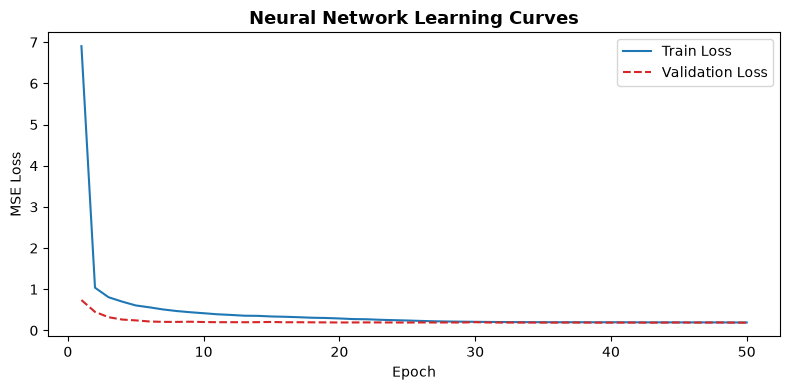

Saved: figures/nn_learning_curves.png


In [12]:
# ── Learning curves ───────────────────────────────────────────────────────────
plt.figure(figsize=(8, 4))
plt.plot(range(1, EPOCHS + 1), train_losses, label='Train Loss', color='#1f77b4')
plt.plot(range(1, EPOCHS + 1), val_losses,   label='Validation Loss', color='#d62728', linestyle='--')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Neural Network Learning Curves', fontsize=13, fontweight='bold')
plt.legend()
plt.tight_layout()
plt.savefig('figures/nn_learning_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: figures/nn_learning_curves.png')

In [13]:
# ── Neural network test evaluation ────────────────────────────────────────────
model.eval()
with torch.no_grad():
    y_pred_nn_test = model(X_test_tensor).numpy()

nn_test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_nn_test))
nn_test_mae  = mean_absolute_error(y_test, y_pred_nn_test)
nn_test_r2   = r2_score(y_test, y_pred_nn_test)

print('Neural Network — Hold-out Test Set Results:')
print(f'  RMSE: {nn_test_rmse:.4f}')
print(f'  MAE:  {nn_test_mae:.4f}')
print(f'  R²:   {nn_test_r2:.4f}')

Neural Network — Hold-out Test Set Results:
  RMSE: 0.4299
  MAE:  0.3231
  R²:   0.5766


In [14]:
# ── 5-fold CV for neural network (lightweight version) ────────────────────────
# WHY: Ensures the NN comparison is on equivalent ground as polynomial regression.
# Full training loop per fold; each fold trains for 30 epochs to keep runtime reasonable.

nn_rmse_scores = []
nn_mae_scores  = []
nn_r2_scores   = []

kf_nn = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for fold, (train_idx, val_idx) in enumerate(kf_nn.split(X_train_scaled), 1):
    X_fold_train = torch.tensor(X_train_scaled[train_idx], dtype=torch.float32)
    y_fold_train = torch.tensor(y_train[train_idx], dtype=torch.float32)
    X_fold_val   = torch.tensor(X_train_scaled[val_idx], dtype=torch.float32)
    y_fold_val   = y_train[val_idx]

    fold_model = AirbnbNet(INPUT_DIM)
    fold_optim = torch.optim.Adam(fold_model.parameters(), lr=LEARNING_RATE)
    fold_ds    = TensorDataset(X_fold_train, y_fold_train)
    fold_dl    = DataLoader(fold_ds, batch_size=BATCH_SIZE, shuffle=True)

    fold_model.train()
    for _ in range(30):  # 30 epochs per fold
        for X_b, y_b in fold_dl:
            fold_optim.zero_grad()
            loss = criterion(fold_model(X_b), y_b)
            loss.backward()
            fold_optim.step()

    fold_model.eval()
    with torch.no_grad():
        y_pred_fold = fold_model(X_fold_val).numpy()

    rmse = np.sqrt(mean_squared_error(y_fold_val, y_pred_fold))
    mae  = mean_absolute_error(y_fold_val, y_pred_fold)
    r2   = r2_score(y_fold_val, y_pred_fold)

    nn_rmse_scores.append(rmse)
    nn_mae_scores.append(mae)
    nn_r2_scores.append(r2)
    print(f'  Fold {fold}: RMSE={rmse:.4f}  MAE={mae:.4f}  R²={r2:.4f}')

print(f'\n5-Fold CV — Neural Network:')
print(f'  RMSE: {np.mean(nn_rmse_scores):.4f} ± {np.std(nn_rmse_scores):.4f}')
print(f'  MAE:  {np.mean(nn_mae_scores):.4f} ± {np.std(nn_mae_scores):.4f}')
print(f'  R²:   {np.mean(nn_r2_scores):.4f} ± {np.std(nn_r2_scores):.4f}')

  Fold 1: RMSE=0.4406  MAE=0.3250  R²=0.5597
  Fold 2: RMSE=0.4416  MAE=0.3327  R²=0.5664
  Fold 3: RMSE=0.6448  MAE=0.5109  R²=0.0354
  Fold 4: RMSE=0.4433  MAE=0.3295  R²=0.5628
  Fold 5: RMSE=0.4533  MAE=0.3323  R²=0.5122

5-Fold CV — Neural Network:
  RMSE: 0.4847 ± 0.0802
  MAE:  0.3661 ± 0.0725
  R²:   0.4473 ± 0.2069


## Section 6: Model Comparison

In [15]:
# ── Comparison table ──────────────────────────────────────────────────────────
comparison = pd.DataFrame({
    'Model': ['Polynomial Regression (deg 2)', 'Feedforward Neural Network'],
    'RMSE (test)': [f'{poly_test_rmse:.4f}', f'{nn_test_rmse:.4f}'],
    'MAE (test)':  [f'{poly_test_mae:.4f}',  f'{nn_test_mae:.4f}'],
    'R² (test)':   [f'{poly_test_r2:.4f}',   f'{nn_test_r2:.4f}'],
    'CV RMSE (mean ± std)': [
        f'{np.mean(poly_rmse_scores):.4f} ± {np.std(poly_rmse_scores):.4f}',
        f'{np.mean(nn_rmse_scores):.4f} ± {np.std(nn_rmse_scores):.4f}'
    ]
})
print(comparison.to_string(index=False))

                        Model RMSE (test) MAE (test) R² (test) CV RMSE (mean ± std)
Polynomial Regression (deg 2)      0.4418     0.3319    0.5528      0.4497 ± 0.0051
   Feedforward Neural Network      0.4299     0.3231    0.5766      0.4847 ± 0.0802


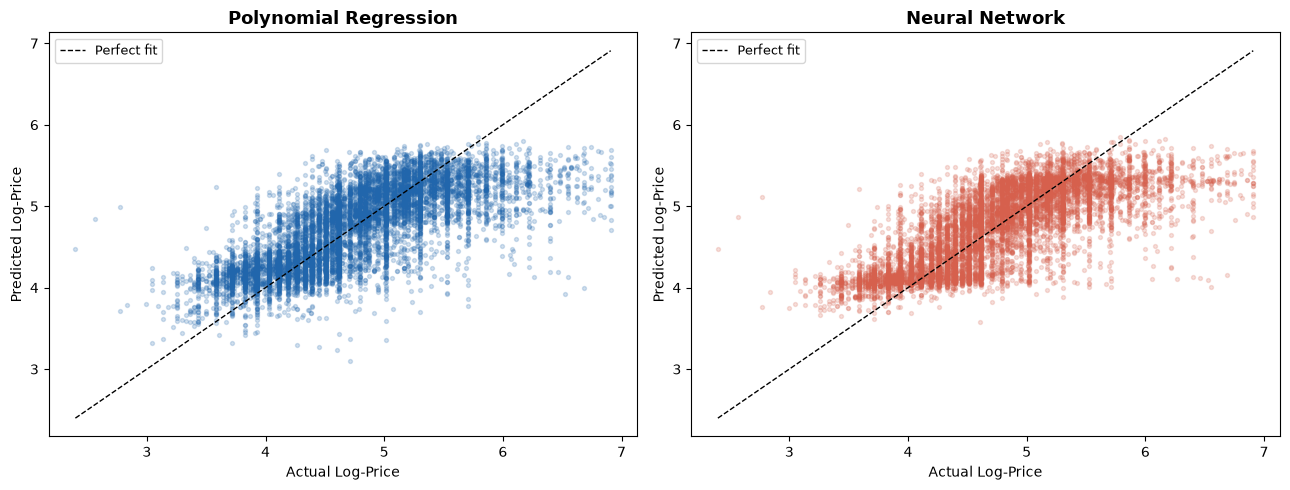

Saved: figures/model_comparison.png


In [16]:
# ── Predicted vs Actual plots ─────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, y_pred, title, colour in zip(
    axes,
    [y_pred_poly_test, y_pred_nn_test],
    ['Polynomial Regression', 'Neural Network'],
    ['#2166ac', '#d6604d']
):
    ax.scatter(y_test, y_pred, alpha=0.2, s=8, color=colour)
    lim = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
    ax.plot(lim, lim, 'k--', linewidth=1, label='Perfect fit')
    ax.set_xlabel('Actual Log-Price')
    ax.set_ylabel('Predicted Log-Price')
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig('figures/model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: figures/model_comparison.png')

### Demonstration: Price Recommendations

The trained models are applied as a host-facing pricing tool. The first table shows recommendations for three illustrative listings; the second compares both models' predictions with the actual prices of three real listings from the hold-out test set. Predictions are converted from log-price back to dollars per night with `np.expm1()`.

In [17]:
# ── Demonstration: recommendations for illustrative listings ──────────────────
examples = pd.DataFrame([
    {'Listing': 'Manhattan entire home, 2 km from Times Square',
     'distance_times_square_km': 2.0, 'room_type': 'Entire home/apt',
     'neighbourhood_group': 'Manhattan', 'minimum_nights': 2,
     'reviews_per_month': 1.5, 'availability_365': 180},
    {'Listing': 'Brooklyn private room, 8 km from Times Square',
     'distance_times_square_km': 8.0, 'room_type': 'Private room',
     'neighbourhood_group': 'Brooklyn', 'minimum_nights': 3,
     'reviews_per_month': 1.0, 'availability_365': 90},
    {'Listing': 'Staten Island entire home, 25 km from Times Square',
     'distance_times_square_km': 25.0, 'room_type': 'Entire home/apt',
     'neighbourhood_group': 'Staten Island', 'minimum_nights': 2,
     'reviews_per_month': 0.5, 'availability_365': 200},
])

# Apply the same encoding and scaling used in training
examples['room_type_enc'] = le_room.transform(examples['room_type'])
examples['borough_enc']   = le_borough.transform(examples['neighbourhood_group'])
X_demo = scaler.transform(examples[FEATURES].values)

pred_poly = np.expm1(poly_pipeline.predict(X_demo))
model.eval()
with torch.no_grad():
    pred_nn = np.expm1(model(torch.tensor(X_demo, dtype=torch.float32)).numpy())

examples['Polynomial'] = [f'${p:,.0f}' for p in pred_poly]
examples['Neural network'] = [f'${p:,.0f}' for p in pred_nn]
print('Recommended nightly price — illustrative listings')
print(examples[['Listing', 'Polynomial', 'Neural network']].to_string(index=False))

# ── Comparison with real hold-out listings ────────────────────────────────────
real = pd.DataFrame(X_test[:3], columns=FEATURES)
real['Borough']   = le_borough.inverse_transform(real['borough_enc'].astype(int))
real['Room type'] = le_room.inverse_transform(real['room_type_enc'].astype(int))
real['Distance (km)']  = real['distance_times_square_km'].round(1)
real['Actual']         = [f'${p:,.0f}' for p in np.expm1(y_test[:3])]
real['Polynomial']     = [f'${p:,.0f}' for p in np.expm1(y_pred_poly_test[:3])]
real['Neural network'] = [f'${p:,.0f}' for p in np.expm1(y_pred_nn_test[:3])]
print('\nReal test-set listings — actual vs predicted')
print(real[['Borough', 'Room type', 'Distance (km)', 'Actual',
            'Polynomial', 'Neural network']].to_string(index=False))

Recommended nightly price — illustrative listings
                                           Listing Polynomial Neural network
     Manhattan entire home, 2 km from Times Square       $248           $246
     Brooklyn private room, 8 km from Times Square        $71            $67
Staten Island entire home, 25 km from Times Square       $142           $130

Real test-set listings — actual vs predicted
  Borough    Room type  Distance (km) Actual Polynomial Neural network
 Brooklyn Private room           10.0    $85        $60            $61
Manhattan Private room            1.1   $180       $134           $164
 Brooklyn Private room            5.0   $100        $84            $89


## Section 7: Explainability — SHAP Analysis

**Why SHAP?**
SHAP (SHapley Additive exPlanations) provides a theoretically grounded, model-agnostic framework for interpreting predictions (Lundberg & Lee, 2017). Unlike feature importance from linear coefficients (which do not account for interactions), SHAP values quantify each feature's marginal contribution to each individual prediction, enabling both global and local interpretability. Using the same explainability method for both models ensures a fair comparison.

Using 200 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.


Computing SHAP values for Polynomial Regression...


  0%|          | 0/300 [00:00<?, ?it/s]

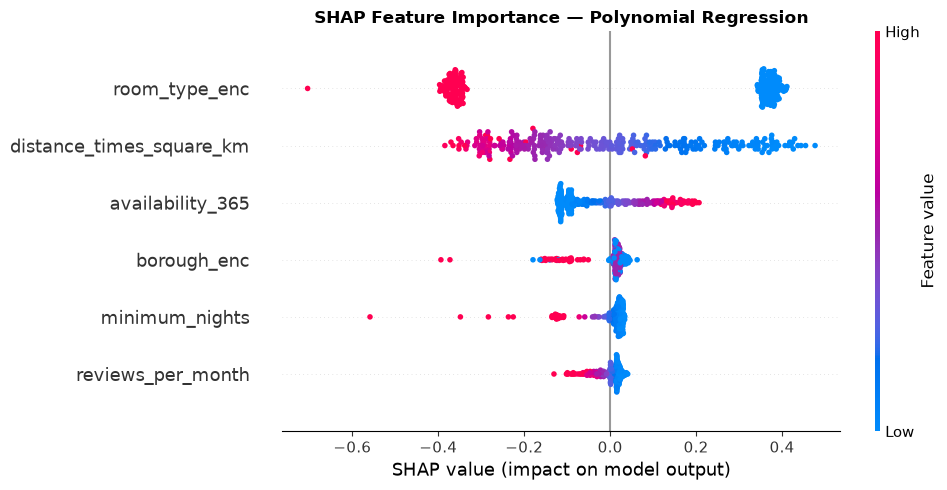

Saved: figures/shap_poly.png


In [18]:
# ── SHAP for Polynomial Regression ───────────────────────────────────────────
# WHY KernelExplainer for poly regression:
# The Pipeline includes polynomial feature expansion, making LinearExplainer
# unsuitable. KernelExplainer treats the model as a black box, which is
# consistent with the approach applied to the neural network (Lundberg & Lee, 2017).

print('Computing SHAP values for Polynomial Regression...')
background_poly = shap.sample(X_train_scaled, 200, random_state=RANDOM_STATE)
explainer_poly  = shap.KernelExplainer(poly_pipeline.predict, background_poly)

explain_data_poly  = X_test_scaled[:300]
shap_values_poly   = explainer_poly.shap_values(explain_data_poly, nsamples=100)

plt.figure()
shap.summary_plot(
    shap_values_poly, explain_data_poly,
    feature_names=FEATURES,
    show=False, plot_size=(10, 5)
)
plt.title('SHAP Feature Importance — Polynomial Regression', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/shap_poly.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: figures/shap_poly.png')

Using 200 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.


Computing SHAP values for Neural Network...
Check — max difference vs PyTorch predictions: 1.43e-06


  0%|          | 0/300 [00:00<?, ?it/s]

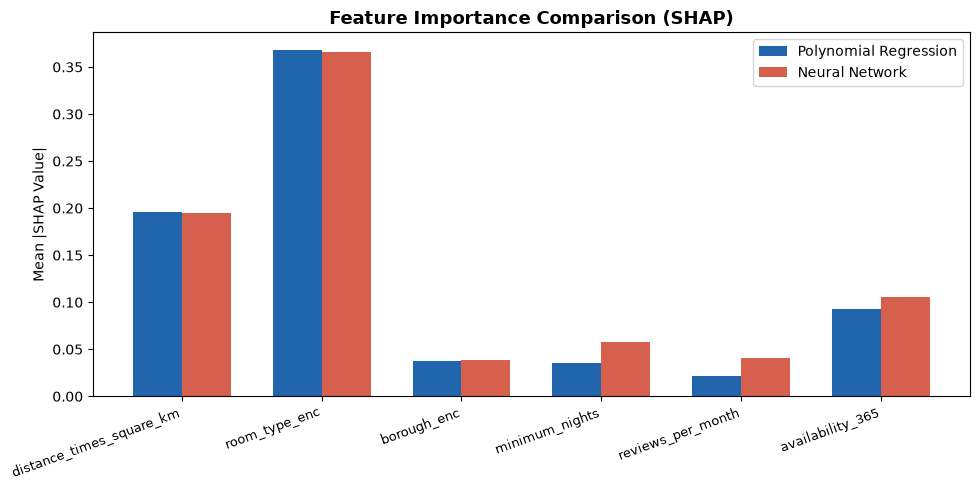

Saved: figures/shap_comparison.png


In [19]:
# ── SHAP for Neural Network ───────────────────────────────────────────────────
# WHY a NumPy forward pass: KernelExplainer queries the model many thousands of
# times. The trained network's weights are copied into an equivalent NumPy
# implementation (dropout disabled, as at inference), which is faster to query
# and is verified below to reproduce the PyTorch predictions.
print('Computing SHAP values for Neural Network...')

linear_layers = [m for m in model.network if isinstance(m, nn.Linear)]
weights = [(l.weight.detach().numpy().T.copy(), l.bias.detach().numpy().copy())
           for l in linear_layers]

def nn_predict(X_np):
    """NumPy forward pass: Linear → ReLU for hidden layers, linear output."""
    h = np.asarray(X_np, dtype=np.float32)
    for i, (W, b) in enumerate(weights):
        h = h @ W + b
        if i < len(weights) - 1:
            h = np.maximum(h, 0)
    return h[:, 0]

# Verify the NumPy forward pass reproduces the PyTorch predictions
max_diff = np.max(np.abs(nn_predict(X_test_scaled) - y_pred_nn_test))
print(f'Check — max difference vs PyTorch predictions: {max_diff:.2e}')

background_nn = shap.sample(X_train_scaled, 200, random_state=RANDOM_STATE)
explainer_nn  = shap.KernelExplainer(nn_predict, background_nn)

explain_data_nn = X_test_scaled[:300]
shap_values_nn  = explainer_nn.shap_values(explain_data_nn, nsamples=100)

# ── Side-by-side mean |SHAP| comparison ──────────────────────────────────────
mean_shap_poly = np.abs(shap_values_poly).mean(axis=0)
mean_shap_nn   = np.abs(shap_values_nn).mean(axis=0)

x_pos = np.arange(len(FEATURES))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x_pos - width/2, mean_shap_poly, width, label='Polynomial Regression', color='#2166ac')
ax.bar(x_pos + width/2, mean_shap_nn,   width, label='Neural Network',        color='#d6604d')
ax.set_xticks(x_pos)
ax.set_xticklabels(FEATURES, rotation=20, ha='right', fontsize=9)
ax.set_ylabel('Mean |SHAP Value|')
ax.set_title('Feature Importance Comparison (SHAP)', fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('figures/shap_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: figures/shap_comparison.png')

## Section 8: Bias and Subgroup Analysis

**Why subgroup analysis?**
Aggregate metrics can mask disparate performance across subgroups — a model that performs well on average may underserve particular boroughs or room types. This reflects the fairness principle that models should not systematically disadvantage specific groups in practice (Barocas et al., 2019). Here we examine RMSE by borough and room type to detect performance disparities.

In [20]:
# ── Build a test-set dataframe with predictions ───────────────────────────────

# Rebuild test set with metadata for subgroup analysis
_, df_test = train_test_split(
    df, test_size=0.2, random_state=RANDOM_STATE,
    stratify=df['neighbourhood_group']
)
df_test = df_test.copy()
df_test['pred_poly'] = y_pred_poly_test
df_test['pred_nn']   = y_pred_nn_test
df_test['actual']    = y_test

def rmse_group(df_sub, pred_col):
    return np.sqrt(mean_squared_error(df_sub['actual'], df_sub[pred_col]))

# RMSE by borough
borough_rmse = df_test.groupby('neighbourhood_group').apply(
    lambda g: pd.Series({
        'Polynomial RMSE': rmse_group(g, 'pred_poly'),
        'Neural Net RMSE': rmse_group(g, 'pred_nn'),
        'n': len(g)
    })
).reset_index()

print('RMSE by Borough:')
print(borough_rmse.to_string(index=False))

RMSE by Borough:
neighbourhood_group  Polynomial RMSE  Neural Net RMSE      n
              Bronx         0.499915         0.467911  218.0
           Brooklyn         0.427106         0.419669 4008.0
          Manhattan         0.452160         0.439573 4298.0
             Queens         0.425347         0.410168 1131.0
      Staten Island         0.635410         0.565864   74.0


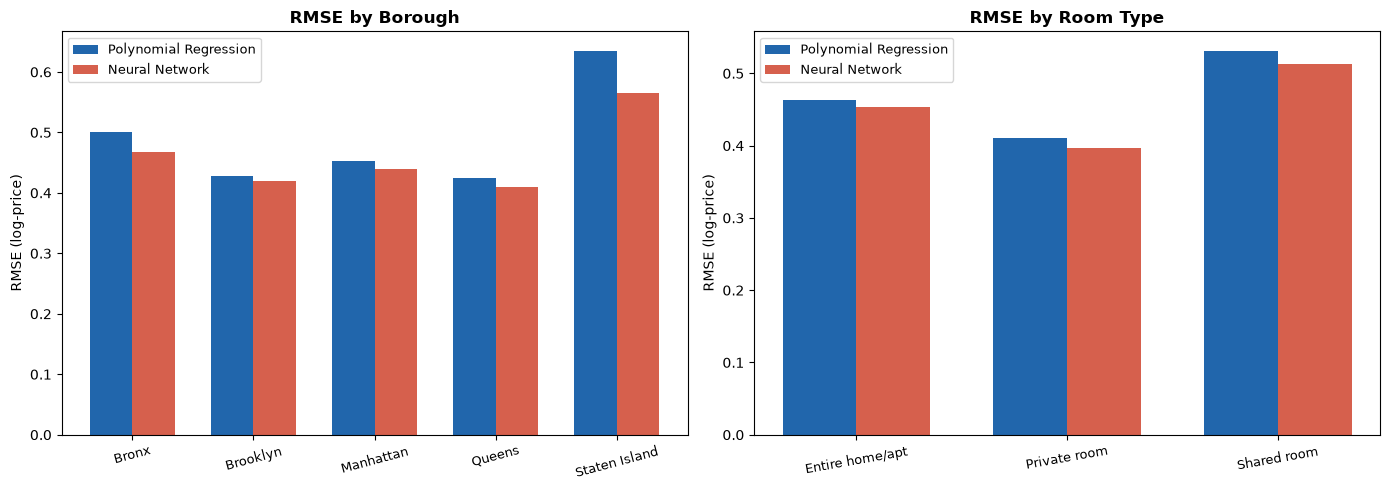

Saved: figures/bias_borough.png


In [21]:
# ── Plot bias by borough ──────────────────────────────────────────────────────
x_pos = np.arange(len(borough_rmse))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Borough comparison
axes[0].bar(x_pos - width/2, borough_rmse['Polynomial RMSE'], width,
            label='Polynomial Regression', color='#2166ac')
axes[0].bar(x_pos + width/2, borough_rmse['Neural Net RMSE'],  width,
            label='Neural Network',        color='#d6604d')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(borough_rmse['neighbourhood_group'], rotation=15, fontsize=9)
axes[0].set_ylabel('RMSE (log-price)')
axes[0].set_title('RMSE by Borough', fontsize=12, fontweight='bold')
axes[0].legend(fontsize=9)

# Room type comparison
room_rmse = df_test.groupby('room_type').apply(
    lambda g: pd.Series({
        'Polynomial RMSE': rmse_group(g, 'pred_poly'),
        'Neural Net RMSE': rmse_group(g, 'pred_nn'),
        'n': len(g)
    })
).reset_index()

x_room = np.arange(len(room_rmse))
axes[1].bar(x_room - width/2, room_rmse['Polynomial RMSE'], width,
            label='Polynomial Regression', color='#2166ac')
axes[1].bar(x_room + width/2, room_rmse['Neural Net RMSE'],  width,
            label='Neural Network',        color='#d6604d')
axes[1].set_xticks(x_room)
axes[1].set_xticklabels(room_rmse['room_type'], rotation=10, fontsize=9)
axes[1].set_ylabel('RMSE (log-price)')
axes[1].set_title('RMSE by Room Type', fontsize=12, fontweight='bold')
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig('figures/bias_borough.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: figures/bias_borough.png')

## Section 9: Ethical Considerations

### Data Privacy
The dataset (Dgomonov, 2019) was originally compiled by Inside Airbnb from publicly visible listings. Hosts did not consent to their listings being used for machine learning research, so the data should be handled with care even though it is public. The prepared dataset used here excludes host names and host IDs, and contains no payment details or guest information. This reflects the principle of data minimisation (Floridi et al., 2018), which should also apply to any production system.

### Algorithmic Fairness
If the model is used to recommend prices to hosts, its errors have direct consequences. A false negative (an under-priced recommendation) reduces host income, while a false positive (an over-priced recommendation) reduces bookings and guest affordability. The predicted-vs-actual plots in Section 6 show that both models compress extreme prices, under-pricing high-value listings and over-pricing budget ones.

### Bias and Harm
The subgroup analysis in Section 8 shows that error is highest where data is scarcest: Staten Island (371 listings, 0.8% of the data), the Bronx and shared rooms. Hosts in these groups would receive the least reliable recommendations. The SHAP analysis in Section 7 shows that `borough_enc` contributes little directly (mean |SHAP| ≈ 0.04), with location captured mainly through distance from Times Square; however, distance and borough are correlated, so geographic effects cannot be fully separated. These disparities should be disclosed in deployment documentation, monitored by subgroup, and addressed through additional data collection or reweighting. Recommendations should support host decisions rather than set prices automatically.

**References:**  
Barocas, S., Hardt, M. and Narayanan, A. (2019) *Fairness and Machine Learning*. fairmlbook.org.  
Dgomonov (2019) *New York City Airbnb Open Data*. Kaggle.  
Floridi, L. et al. (2018) 'AI4People — an ethical framework for a good AI society', *Minds and Machines*, 28(4), pp. 689–707.

## Section 10: Deployment Considerations

### Recommended Model for Deployment: Polynomial Regression

The neural network achieved slightly better hold-out performance (RMSE 0.430 vs 0.442; R² 0.577 vs 0.553). However, polynomial regression is recommended for deployment for the following reasons:

1. **Stability**: Cross-validation RMSE varied far less across folds (± 0.005 vs ± 0.080). One neural network fold failed to train effectively (R² = 0.035), indicating sensitivity to initialisation and training conditions.
2. **Comparable accuracy**: The neural network's advantage is small — a typical error of about 38% versus 39% of the actual price.
3. **Interpretability**: The model is linear in its parameters, so its behaviour can be audited and explained to hosts and platform policy teams.
4. **Operational simplicity**: The fitted pipeline is a small scikit-learn object with fast CPU inference and deterministic retraining. Both models could run on CPU at this scale, so the recommendation rests on reliability rather than hardware.

### Deployment Architecture (Cloud)
- **Training platform**: AWS SageMaker — managed training environment
- **Model serving**: SageMaker Endpoints → REST API for inference
- **Monitoring**: SageMaker Model Monitor for data drift, plus RMSE tracked by borough and room type
- **Retraining trigger**: Monthly, or when RMSE on recent data exceeds a threshold (e.g. 0.05 above baseline)
- **Versioning**: MLflow for experiment tracking; S3 for model artefact storage

### Scalability Notes
The polynomial pipeline serialises to a small file and supports fast batch prediction across all active listings. Its retraining is deterministic, whereas the neural network would need early stopping and checks across multiple random seeds at each retraining to guard against the failure seen in fold 3.

## Section 11: Final Summary

In [22]:
print('=' * 65)
print('  FINAL RESULTS SUMMARY')
print('=' * 65)
print(f'  {'Model':<35} {'RMSE':>8} {'MAE':>8} {'R²':>8}')
print('-' * 65)
print(f'  {'Polynomial Regression (deg 2)':<35} {poly_test_rmse:>8.4f} {poly_test_mae:>8.4f} {poly_test_r2:>8.4f}')
print(f'  {'Feedforward Neural Network':<35} {nn_test_rmse:>8.4f} {nn_test_mae:>8.4f} {nn_test_r2:>8.4f}')
print('=' * 65)

winner_rmse = 'Polynomial Regression' if poly_test_rmse < nn_test_rmse else 'Neural Network'
winner_r2   = 'Polynomial Regression' if poly_test_r2   > nn_test_r2   else 'Neural Network'
print(f'  Best RMSE: {winner_rmse}')
print(f'  Best R²:   {winner_r2}')
print(f'  Recommended for deployment: Polynomial Regression')
print('  (Reasons: interpretability, stability, inference speed)')
print('=' * 65)

print('\nFigures saved to ./figures/')
for f in sorted(os.listdir('figures')):
    print(f'  - figures/{f}')

  FINAL RESULTS SUMMARY
  Model                                   RMSE      MAE       R²
-----------------------------------------------------------------
  Polynomial Regression (deg 2)         0.4418   0.3319   0.5528
  Feedforward Neural Network            0.4299   0.3231   0.5766
  Best RMSE: Neural Network
  Best R²:   Neural Network
  Recommended for deployment: Polynomial Regression
  (Reasons: interpretability, stability, inference speed)

Figures saved to ./figures/
  - figures/bias_borough.png
  - figures/eda_categories.png
  - figures/eda_distributions.png
  - figures/model_comparison.png
  - figures/nn_learning_curves.png
  - figures/shap_comparison.png
  - figures/shap_poly.png


## References

Barocas, S., Hardt, M. and Narayanan, A. (2019) *Fairness and Machine Learning*. Available at: https://fairmlbook.org (Accessed: 9 October 2026).

Dgomonov (2019) *New York City Airbnb Open Data*. Kaggle. Available at: https://www.kaggle.com/datasets/dgomonov/new-york-city-airbnb-open-data (Accessed: 3 September 2026).

Floridi, L., Cowls, J., Beltrametti, M., Chatila, R., Chazerand, P., Dignum, V., Luetge, C., Madelin, R., Pagallo, U., Rossi, F., Schafer, B., Valcke, P. and Vayena, E. (2018) 'AI4People — an ethical framework for a good AI society: opportunities, risks, principles, and recommendations', *Minds and Machines*, 28(4), pp. 689–707.

Goodfellow, I., Bengio, Y. and Courville, A. (2016) *Deep Learning*. Cambridge, MA: MIT Press.

James, G., Witten, D., Hastie, T. and Tibshirani, R. (2021) *An Introduction to Statistical Learning with Applications in R*. 2nd edn. New York: Springer.

Kingma, D. P. and Ba, J. (2015) 'Adam: a method for stochastic optimization', *3rd International Conference on Learning Representations (ICLR)*. Available at: https://arxiv.org/abs/1412.6980.

Kohavi, R. (1995) 'A study of cross-validation and bootstrap for accuracy estimation and model selection', *Proceedings of the 14th International Joint Conference on Artificial Intelligence*, pp. 1137–1143.

LeCun, Y., Bengio, Y. and Hinton, G. (2015) 'Deep learning', *Nature*, 521(7553), pp. 436–444.

Lundberg, S. M. and Lee, S. I. (2017) 'A unified approach to interpreting model predictions', *Advances in Neural Information Processing Systems*, 30, pp. 4765–4774.

Paszke, A. et al. (2019) 'PyTorch: an imperative style, high-performance deep learning library', *Advances in Neural Information Processing Systems*, 32, pp. 8024–8035.

Pedregosa, F. et al. (2011) 'Scikit-learn: machine learning in Python', *Journal of Machine Learning Research*, 12, pp. 2825–2830.

Shwartz-Ziv, R. and Armon, A. (2022) 'Tabular data: deep learning is not all you need', *Information Fusion*, 81, pp. 84–90.